In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from transformers import AutoModel

MODEL_PATH = r"C:\MODELS\magiv2"

model = AutoModel.from_pretrained(
    MODEL_PATH,
    trust_remote_code=True,
    local_files_only=True,
).cuda().eval()

# print(type(model))

Encountered exception while importing pulp: No module named 'pulp'


ImportError: This modeling file requires the following packages that were not found in your environment: pulp. Run `pip install pulp`

In [ ]:
def read_image(path):
    with open(path, "rb") as f:
        return np.array(Image.open(f).convert("L").convert("RGB"))

## CHOOSE-SEQUENCE

In [ ]:
SEQUENCE_ROOT = Path(
    r"C:\Users\ESHAAN\BYTE\Applied-Task\Magi\TaskData\development\images\seq_0dc2e3d874c804fc"
)

PAGE_FILES = sorted(SEQUENCE_ROOT.glob("*.png"))
chapter_pages = [read_image(p) for p in PAGE_FILES]

print("Sequence:", SEQUENCE_ROOT.name)
print("Pages:", [p.name for p in PAGE_FILES])

Sequence: seq_0dc2e3d874c804fc
Pages: ['01.png', '02.png', '03.png']


## VIEW-SEQUENCE

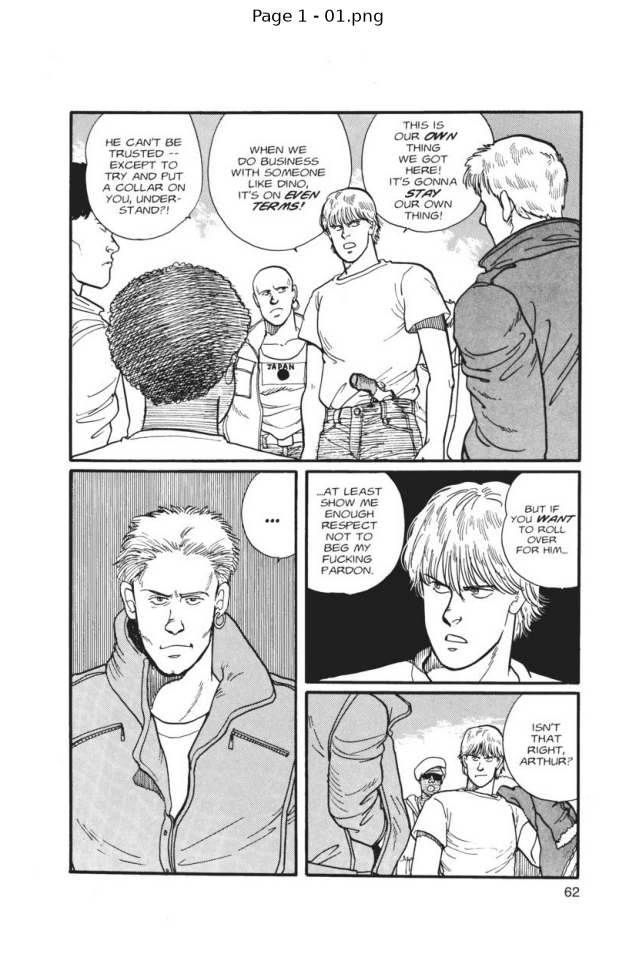

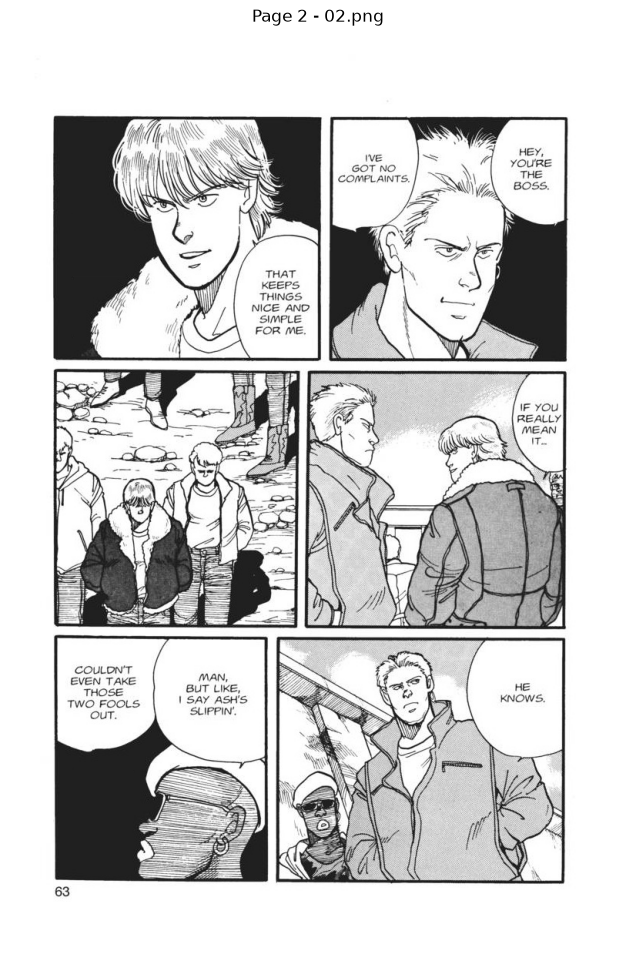

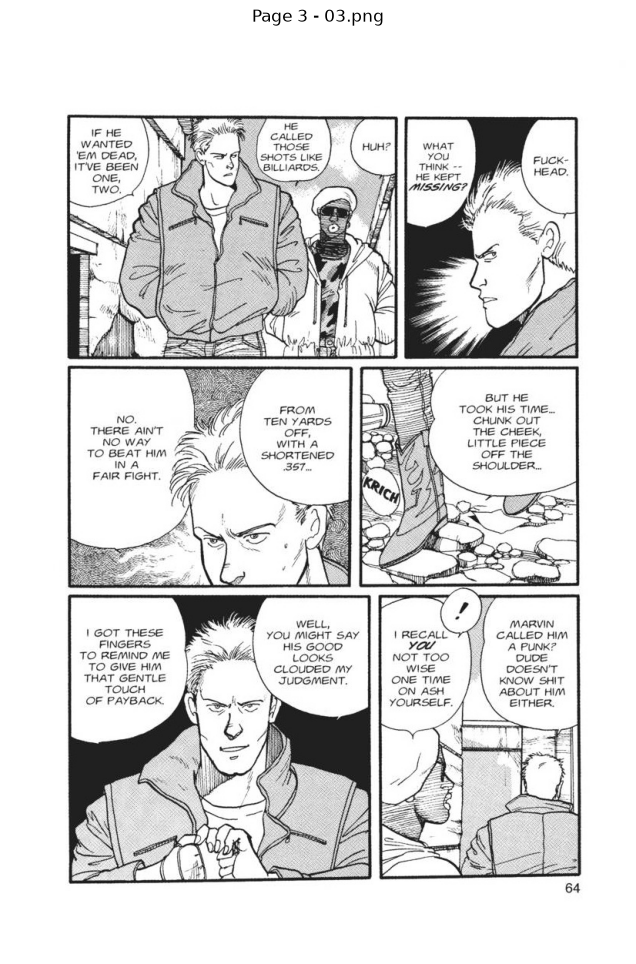

In [ ]:
def view_sequence(chapter_pages, page_files=None):
    for i, image in enumerate(chapter_pages):
        plt.figure(figsize=(8, 12))
        plt.imshow(image)
        title = f"Page {i+1}"
        if page_files is not None:
            title += f" - {page_files[i].name}"
        plt.title(title)
        plt.axis("off")
        plt.show()

view_sequence(chapter_pages, PAGE_FILES)

## RUN-MAGIV2

In [ ]:
character_bank = {
    "images": [],
    "names": [],
}

with torch.no_grad():
    per_page_results = model.do_chapter_wide_prediction(
        chapter_pages,
        character_bank,
        use_tqdm=True,
        do_ocr=True,
    )

print(per_page_results[0].keys())

100%|██████████| 1/1 [00:04<00:00,  4.85s/it]

dict_keys(['panels', 'texts', 'characters', 'tails', 'text_character_associations', 'text_tail_associations', 'character_cluster_labels', 'is_essential_text', 'ocr', 'character_names'])


In [ ]:
page = 0
for i in per_page_results[page] :
    print(f"{i} : len : {len(per_page_results[page][i])}" )
    print(f"{i} : output : {per_page_results[page][i]}" )
    print('\n')

panels : len : 4
panels : output : [[72.05891418457031, 99.60946655273438, 743.0464477539062, 561.5567016601562], [377.14324951171875, 571.387451171875, 743.2175903320312, 858.001708984375], [378.0970153808594, 856.7744750976562, 739.5032348632812, 1107.761962890625], [73.7636947631836, 568.8917846679688, 373.61639404296875, 1104.46630859375]]


texts : len : 7
texts : output : [[491.7005615234375, 115.26335144042969, 585.6625366210938, 249.1288604736328], [284.1544494628906, 145.4463653564453, 410.4164733886719, 238.1248779296875], [117.97957611083984, 137.41587829589844, 231.5010528564453, 242.34912109375], [649.3109741210938, 615.7588500976562, 736.6842041015625, 685.5227661132812], [398.9065246582031, 592.5792846679688, 482.6698303222656, 712.1756591796875], [660.7257080078125, 899.6484985351562, 733.7633056640625, 961.0811157226562], [325.44903564453125, 628.831787109375, 358.965576171875, 648.5642700195312]]


characters : len : 11
characters : output : [[514.8379516601562, 904.9

In [ ]:
# Reuse the PaddleOCR environment and settings from 1pageTest stage 2.
# Paddle runs in its own Python process so this notebook can keep its Magi kernel.
import json
import subprocess
import tempfile
from IPython.display import display

PADDLE_PYTHON = Path(
    r"C:\Users\ESHAAN\BYTE\Applied-Task\MultiModelSystem\.venvOCR\Scripts\python.exe"
)
PADDLE_LANGUAGE = "en"
paddle_ocr_results = {}  # Page index -> records, independent of Magi's OCR.

_PADDLE_WORKER = r"""
import json
import sys
import numpy as np
from PIL import Image
from paddleocr import PaddleOCR

payload = json.load(sys.stdin)
ocr = PaddleOCR(
    lang=payload["language"],
    use_doc_orientation_classify=False,
    use_doc_unwarping=False,
    use_textline_orientation=False,
)
records = []
for crop_path in payload["crops"]:
    with Image.open(crop_path) as image:
        crop = np.asarray(image.convert("RGB"))
    lines = []
    for result in ocr.predict(input=crop):
        for text, score in zip(result["rec_texts"], result["rec_scores"]):
            lines.append({"text": str(text), "confidence": float(score)})
    records.append({"text": " ".join(line["text"] for line in lines), "lines": lines})
print("PADDLE_RESULTS_JSON=" + json.dumps(records, ensure_ascii=True), flush=True)
"""


def page_bubbles_paddle(page_image, page_text_boxes, page_index=0):
    """OCR Magi text-box crops; return one record per box in the original order."""
    if not PADDLE_PYTHON.is_file():
        raise FileNotFoundError(f"PaddleOCR Python environment not found: {PADDLE_PYTHON}")
    image = Image.fromarray(np.asarray(page_image, dtype=np.uint8)).convert("RGB")
    records, previews, valid_indices = [], [], []

    with tempfile.TemporaryDirectory(prefix="magi_paddle_") as crop_dir:
        crop_paths = []
        for box_index, box in enumerate(page_text_boxes):
            coordinates = np.asarray(box, dtype=float)
            if coordinates.shape != (4,) or not np.isfinite(coordinates).all():
                raise ValueError(f"T{box_index + 1}: expected four finite xyxy coordinates")
            x1, y1, x2, y2 = coordinates
            crop_box = [
                max(0, min(image.width, int(np.floor(x1)))),
                max(0, min(image.height, int(np.floor(y1)))),
                max(0, min(image.width, int(np.ceil(x2)))),
                max(0, min(image.height, int(np.ceil(y2)))),
            ]
            record = {
                "page_index": page_index,
                "text_id": f"T{box_index + 1}",
                "box": coordinates.tolist(),
                "crop_box": crop_box,
                "text": "",
                "lines": [],
            }
            records.append(record)
            if crop_box[2] <= crop_box[0] or crop_box[3] <= crop_box[1]:
                record["status"] = "invalid_crop"
                previews.append(None)
                continue
            crop = image.crop(crop_box)
            previews.append(crop)
            crop_path = Path(crop_dir) / f"{record['text_id']}.png"
            crop.save(crop_path)
            crop_paths.append(str(crop_path))
            valid_indices.append(box_index)

        if crop_paths:
            print(f"Running PaddleOCR on {len(crop_paths)} text boxes (page {page_index + 1})...", flush=True)
            process = subprocess.run(
                [str(PADDLE_PYTHON), "-u", "-c", _PADDLE_WORKER],
                input=json.dumps({"language": PADDLE_LANGUAGE, "crops": crop_paths}),
                capture_output=True,
                text=True,
                encoding="utf-8",
                errors="replace",
            )
            if process.returncode:
                raise RuntimeError(
                    "PaddleOCR failed in .venvOCR:\n"
                    + process.stdout[-4000:] + "\n" + process.stderr[-8000:]
                )
            marker = "PADDLE_RESULTS_JSON="
            result_line = next(
                (line[len(marker):] for line in reversed(process.stdout.splitlines())
                 if line.startswith(marker)), None
            )
            if result_line is None:
                raise RuntimeError("PaddleOCR returned no results:\n" + process.stdout[-4000:])
            predictions = json.loads(result_line)
            if len(predictions) != len(valid_indices):
                raise RuntimeError("PaddleOCR result count does not match the crop count")
            for box_index, prediction in zip(valid_indices, predictions):
                records[box_index].update(prediction)
                records[box_index]["status"] = "ok" if prediction["text"].strip() else "no_text"

    paddle_ocr_results[page_index] = records
    for record, crop in zip(records, previews):
        print(f"{record['text_id']} | box={record['box']}")
        print(f"Paddle: {record['text'] or '[no text recognized]'}")
        for line in record["lines"]:
            print(f"  {line['confidence']:.3f}: {line['text']}")
        if crop is not None:
            display(crop)
        else:
            print("[box has no image area after clipping to the page]")
    return records


## PaddleOCR on Magi text boxes
Use the same English PaddleOCR setup as `1pageTest/2_ocr_from_bubbles`. Each Magi text box is cropped from its matching page, and the Paddle text and line confidences are displayed below. `page = 1` selects the second page. Results are available in `paddle_page_results` and `paddle_ocr_results[page]`; Magi results remain available for comparison.
Paddle runs through the existing `.venvOCR` Python environment, so keep the current Magi notebook kernel. Change `PADDLE_LANGUAGE` to `"japan"` for Japanese pages.


Running PaddleOCR on 7 text boxes (page 1)...
T1 | box=[491.7005615234375, 115.26335144042969, 585.6625366210938, 249.1288604736328]
Paddle: THIS IS OUR OWN THING WE GOT HERE! IT'S GONNA STAY OUR OWN THING!
  0.934: THIS IS
  0.994: OUR OWN
  1.000: THING
  1.000: WE GOT
  1.000: HERE!
  1.000: IT'S GONNA
  1.000: STAY
  0.999: OUR OWN
  1.000: THING!


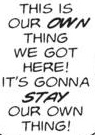

T2 | box=[284.1544494628906, 145.4463653564453, 410.4164733886719, 238.1248779296875]
Paddle: WHEN WE DO BUSINESS WITH SOMEONE LIKE DINO IT'S ON EVEN TERMS!
  0.998: WHEN WE
  0.957: DO BUSINESS
  1.000: WITH SOMEONE
  0.976: LIKE DINO
  0.994: IT'S ON EVEN
  1.000: TERMS!


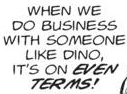

T3 | box=[117.97957611083984, 137.41587829589844, 231.5010528564453, 242.34912109375]
Paddle: HE CAN'T BE TRUSTED EXCEPT TO TRY AND PUT A COLLAR ON YOU, UNDER STAND?!
  1.000: HE CAN'T BE
  1.000: TRUSTED
  1.000: EXCEPT TO
  0.961: TRY AND PUT
  0.983: A COLLAR ON
  0.995: YOU, UNDER
  0.995: STAND?!


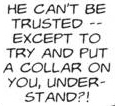

T4 | box=[649.3109741210938, 615.7588500976562, 736.6842041015625, 685.5227661132812]
Paddle: BUT IF YOU WAN TO ROLL OVER FOR HIM.
  0.988: BUT IF
  0.916: YOU WAN
  0.959: TO ROLL
  1.000: OVER
  0.993: FOR HIM.


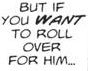

T5 | box=[398.9065246582031, 592.5792846679688, 482.6698303222656, 712.1756591796875]
Paddle: ...AT LEAST SHOW ME ENOUGH RESPECT NOT TO BEG MY FUCKING PARDON.
  0.937: ...AT LEAST
  1.000: SHOW ME
  1.000: ENOUGH
  1.000: RESPECT
  0.999: NOT TO
  0.999: BEG MY
  1.000: FUCKING
  1.000: PARDON.


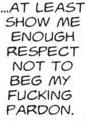

T6 | box=[660.7257080078125, 899.6484985351562, 733.7633056640625, 961.0811157226562]
Paddle: ISN'T THAT RIGHT, ARTHUR?
  1.000: ISN'T
  1.000: THAT
  1.000: RIGHT,
  1.000: ARTHUR?


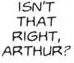

T7 | box=[325.44903564453125, 628.831787109375, 358.965576171875, 648.5642700195312]
Paddle: [no text recognized]


In [ ]:
page = 0
paddle_page_results = page_bubbles_paddle(
    chapter_pages[page], per_page_results[page]["texts"], page_index=page
)


In [ ]:
per_page_results[0]['ocr']

["This is our OOW thing we got here! It's gonna $7AY our own thing!",
 "When we do business with someone like Dino, it's on EVEN 7GR/15!",
 "HE CAN'T BE TRUSTED -- EXCEPT TO TRY AND PUT A COLLAR ON YOU, UNDER- STAND?!",
 'but if you WANT to roll over for him...',
 '...at least show me enough respect not to beg my fucking pardon.',
 "Isn't that right, Arthur?",
 '...']

In [ ]:
[i['text'] for i in paddle_ocr_results[0]]

["THIS IS OUR OWN THING WE GOT HERE! IT'S GONNA STAY OUR OWN THING!",
 "WHEN WE DO BUSINESS WITH SOMEONE LIKE DINO IT'S ON EVEN TERMS!",
 "HE CAN'T BE TRUSTED EXCEPT TO TRY AND PUT A COLLAR ON YOU, UNDER STAND?!",
 'BUT IF YOU WAN TO ROLL OVER FOR HIM.',
 '...AT LEAST SHOW ME ENOUGH RESPECT NOT TO BEG MY FUCKING PARDON.',
 "ISN'T THAT RIGHT, ARTHUR?",
 '']

## Select OCR for each text box
Run after Magi prediction (`do_ocr=True`) and Paddle setup. Paddle results already calculated for this page are reused; set `rerun_paddle=True` to calculate them again.

Selection rules:
- If only one output passes the sanity check, select it.
- If both pass, use `PREFERRED_OCR` (default `"paddle"`). Different passing outputs are marked `disagreement=True`.
- If only one output contains text but fails sanity, keep that text and mark `needs_review=True`. This preserves punctuation-only dialogue such as `...`.
- If both are empty or both nonempty outputs fail sanity, leave selected text empty and mark it for review. Both raw outputs are retained.

Sanity checks reject empty/non-string text, invalid/control characters (allowing line breaks and tabs), and text without any Unicode letters or digits. These are basic validity checks, not spelling or recognition-quality checks.

`selected_ocr_results[page]` stores both OCRs, Paddle line confidences, sanity results, selection source/reason, and review flags. `per_page_results[page]["selected_ocr"]` supplies the selected text to the visualizer; the original `"ocr"` remains Magi's raw output.


In [ ]:
import unicodedata

PREFERRED_OCR = "paddle"  # Tie-breaker when both engines pass ("paddle" or "magi").
selected_ocr_results = {}  # Page index -> per-box decisions with both raw outputs.


def ocr_sanity_check(text):
    """Basic text validity only; this does not verify spelling or OCR accuracy."""
    if text is None:
        return {"passes": False, "reason": "empty", "normalized_text": ""}
    if not isinstance(text, str):
        return {"passes": False, "reason": "not_a_string", "normalized_text": ""}
    normalized = " ".join(text.split())
    if not normalized:
        reason = "empty"
    elif "\ufffd" in text or any(
        unicodedata.category(char) in {"Cc", "Cs"} and char not in "\n\r\t"
        for char in text
    ):
        reason = "invalid_characters"
    elif not any(char.isalnum() for char in normalized):
        reason = "no_letters_or_digits"
    else:
        reason = "ok"
    return {"passes": reason == "ok", "reason": reason, "normalized_text": normalized}


def select_box_ocr(paddle_text, magi_text, prefer="paddle"):
    """Select OCR for one box, keeping raw text, check results, and review flags."""
    if prefer not in {"paddle", "magi"}:
        raise ValueError("prefer must be 'paddle' or 'magi'")
    raw = {"paddle": paddle_text, "magi": magi_text}
    checks = {engine: ocr_sanity_check(text) for engine, text in raw.items()}
    passing = [engine for engine in raw if checks[engine]["passes"]]
    nonempty = [engine for engine in raw if checks[engine]["normalized_text"]]

    if len(passing) == 1:
        selected = passing[0]
        other = "magi" if selected == "paddle" else "paddle"
        reason = "other_empty" if checks[other]["reason"] == "empty" else "only_sanity_pass"
    elif len(passing) == 2:
        selected = prefer
        reason = "both_pass_preferred"
    elif len(nonempty) == 1:
        # Keep the only text, including legitimate punctuation-only dialogue such as '...'.
        selected = nonempty[0]
        reason = "only_nonempty_needs_review"
    else:
        selected = None
        reason = "both_empty" if all(c["reason"] == "empty" for c in checks.values()) else "both_fail_sanity"

    text = checks[selected]["normalized_text"] if selected else ""
    return {
        "paddle_text": paddle_text,
        "magi_text": magi_text,
        "paddle_sanity": checks["paddle"],
        "magi_sanity": checks["magi"],
        "selected_source": selected,
        "selected_text": text,
        "reason": reason,
        "needs_review": not passing,
        "disagreement": len(passing) == 2 and checks["paddle"]["normalized_text"] != checks["magi"]["normalized_text"],
    }


def select_page_ocr(page_result, paddle_records, page_index=0, prefer="paddle"):
    """Align engines by Magi text-box index; reject mismatched crops or counts."""
    boxes = page_result["texts"]
    magi_texts = page_result.get("ocr")
    if magi_texts is None:
        magi_texts = [None] * len(boxes)
    if len(paddle_records) != len(boxes) or len(magi_texts) != len(boxes):
        raise ValueError("OCR counts must match the number of Magi text boxes")
    decisions = []
    for index, (box, paddle_record, magi_text) in enumerate(zip(boxes, paddle_records, magi_texts)):
        text_id = f"T{index + 1}"
        if paddle_record["text_id"] != text_id or paddle_record["page_index"] != page_index:
            raise ValueError(f"{text_id}: Paddle record belongs to a different box or page")
        if not np.array_equal(np.asarray(paddle_record["box"]), np.asarray(box)):
            raise ValueError(f"{text_id}: Paddle crop coordinates do not match the Magi box; rerun Paddle")
        decision = select_box_ocr(paddle_record.get("text"), magi_text, prefer=prefer)
        decision.update({
            "page_index": page_index,
            "text_id": text_id,
            "box": np.asarray(box).tolist(),
            "paddle_lines": paddle_record.get("lines", []),
        })
        decisions.append(decision)
    return decisions


def page_ocr_selection(page_index=0, prefer=None, rerun_paddle=False):
    """Use Magi's do_ocr=True predictions and Paddle OCR on the same text boxes."""
    prefer = PREFERRED_OCR if prefer is None else prefer
    if prefer not in {"paddle", "magi"}:
        raise ValueError("prefer must be 'paddle' or 'magi'")
    page_result = per_page_results[page_index]
    if rerun_paddle or page_index not in paddle_ocr_results:
        page_bubbles_paddle(chapter_pages[page_index], page_result["texts"], page_index=page_index)
    decisions = select_page_ocr(page_result, paddle_ocr_results[page_index], page_index, prefer)
    selected_ocr_results[page_index] = decisions
    # Preserve original Magi OCR; the visualizer uses the separate selected list.
    page_result["selected_ocr"] = [record["selected_text"] for record in decisions]
    for record in decisions:
        print(f"{record['text_id']} | selected={record['selected_source'] or 'none'} | {record['reason']}")
        print(f"  Paddle [{record['paddle_sanity']['reason']}]: {record['paddle_text']!r}")
        print(f"  Magi   [{record['magi_sanity']['reason']}]: {record['magi_text']!r}")
        print(f"  Output: {record['selected_text']!r}" + (" [review]" if record["needs_review"] else ""))
    return decisions


In [ ]:
selected_page_results = page_ocr_selection(page)


T1 | selected=paddle | both_pass_preferred
  Paddle [ok]: "THIS IS OUR OWN THING WE GOT HERE! IT'S GONNA STAY OUR OWN THING!"
  Magi   [ok]: "This is our OOW thing we got here! It's gonna $7AY our own thing!"
  Output: "THIS IS OUR OWN THING WE GOT HERE! IT'S GONNA STAY OUR OWN THING!"
T2 | selected=paddle | both_pass_preferred
  Paddle [ok]: "WHEN WE DO BUSINESS WITH SOMEONE LIKE DINO IT'S ON EVEN TERMS!"
  Magi   [ok]: "When we do business with someone like Dino, it's on EVEN 7GR/15!"
  Output: "WHEN WE DO BUSINESS WITH SOMEONE LIKE DINO IT'S ON EVEN TERMS!"
T3 | selected=paddle | both_pass_preferred
  Paddle [ok]: "HE CAN'T BE TRUSTED EXCEPT TO TRY AND PUT A COLLAR ON YOU, UNDER STAND?!"
  Magi   [ok]: "HE CAN'T BE TRUSTED -- EXCEPT TO TRY AND PUT A COLLAR ON YOU, UNDER- STAND?!"
  Output: "HE CAN'T BE TRUSTED EXCEPT TO TRY AND PUT A COLLAR ON YOU, UNDER STAND?!"
T4 | selected=paddle | both_pass_preferred
  Paddle [ok]: 'BUT IF YOU WAN TO ROLL OVER FOR HIM.'
  Magi   [ok]: 'but if y

## 3. Custom visualizer

In [ ]:
def center(box):
    x1, y1, x2, y2 = box
    return ((x1 + x2) / 2, (y1 + y2) / 2)


def draw_box(ax, box, edgecolor, label=None, linewidth=2, linestyle="-"):
    x1, y1, x2, y2 = box
    rect = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=linewidth,
        edgecolor=edgecolor,
        facecolor="none",
        linestyle=linestyle,
    )
    ax.add_patch(rect)

    if label:
        ax.text(
            x1,
            max(0, y1 - 4),
            label,
            fontsize=8,
            bbox=dict(facecolor="black", alpha=0.65, edgecolor="none"),
            color="white",
        )


def annotate_magi_page(
    image,
    result,
    page_index=0,
    show_panels=True,
    show_texts=True,
    show_characters=True,
    show_tails=True,
    show_same_character=True,
    show_text_character=True,
    show_text_tail=True,
    show_ocr=True,
    show_ids=True,
    save_path=None,
):
    fig, ax = plt.subplots(figsize=(12, 18))
    ax.imshow(image)

    # Panels
    if show_panels:
        for i, box in enumerate(result["panels"]):
            label = f"PN{i+1}" if show_ids else None
            draw_box(ax, box, "green", label)

    # Prefer selected OCR when the selection step has run.
    display_ocr = result.get("selected_ocr", result.get("ocr", []))

    # Text
    if show_texts:
        for i, box in enumerate(result["texts"]):
            essential = True
            if i < len(result.get("is_essential_text", [])):
                essential = bool(result["is_essential_text"][i])

            label = f"T{i+1}" if show_ids else ""
            if show_ocr and i < len(display_ocr):
                text = display_ocr[i]
                if len(text) > 45:
                    text = text[:42] + "..."
                label = f"{label}: {text}" if label else text

            # essential text = red, non-essential = gray
            color = "red" if essential else "gray"
            draw_box(ax, box, color, label)

    # Characters
    if show_characters:
        cluster_labels = result.get("character_cluster_labels", [])
        for i, box in enumerate(result["characters"]):
            cluster = None
            if i < len(cluster_labels):
                cluster = int(cluster_labels[i]) + 1

            label = f"C{i+1}"
            if cluster is not None:
                label += f" / Cl{cluster}"

            draw_box(ax, box, "blue", label if show_ids else None)

    # Tails
    if show_tails:
        for i, box in enumerate(result["tails"]):
            label = f"TAIL{i+1}" if show_ids else None
            draw_box(ax, box, "purple", label)

    # Same-character links
    if show_same_character:
        cluster_labels = result.get("character_cluster_labels", [])
        groups = {}

        for i, label in enumerate(cluster_labels):
            groups.setdefault(int(label), []).append(i)

        for group in groups.values():
            if len(group) < 2:
                continue

            root = group[0]
            x1, y1 = center(result["characters"][root])

            for j in group[1:]:
                x2, y2 = center(result["characters"][j])
                ax.plot([x1, x2], [y1, y2], linewidth=2)

    # Text -> character
    if show_text_character:
        for text_idx, char_idx in result["text_character_associations"]:
            if text_idx >= len(result["texts"]) or char_idx >= len(result["characters"]):
                continue

            x1, y1 = center(result["texts"][text_idx])
            x2, y2 = center(result["characters"][char_idx])

            ax.plot(
                [x1, x2],
                [y1, y2],
                linestyle="--",
                linewidth=2,
            )

            if show_ids:
                mx, my = (x1+x2)/2, (y1+y2)/2
                ax.text(
                    mx, my,
                    f"T{text_idx+1}->C{char_idx+1}",
                    fontsize=7,
                    bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"),
                )

    # Text -> tail
    if show_text_tail:
        for text_idx, tail_idx in result["text_tail_associations"]:
            if text_idx >= len(result["texts"]) or tail_idx >= len(result["tails"]):
                continue

            x1, y1 = center(result["texts"][text_idx])
            x2, y2 = center(result["tails"][tail_idx])

            ax.plot(
                [x1, x2],
                [y1, y2],
                linestyle=":",
                linewidth=2,
            )

            if show_ids:
                mx, my = (x1+x2)/2, (y1+y2)/2
                ax.text(
                    mx, my,
                    f"T{text_idx+1}->TAIL{tail_idx+1}",
                    fontsize=7,
                    bbox=dict(facecolor="white", alpha=0.7, edgecolor="none"),
                )

    ax.set_title(f"MagiV2 annotations - page {page_index + 1}")
    ax.axis("off")
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, bbox_inches="tight", pad_inches=0.05, dpi=150)

    plt.show()

## 4. Easy presets

Use these when you only want one type of MagiV2 output.

In [ ]:
def show_only(kind, page_index=0):
    flags = dict(
        show_panels=False,
        show_texts=False,
        show_characters=False,
        show_tails=False,
        show_same_character=False,
        show_text_character=False,
        show_text_tail=False,
        show_ocr=False,
        show_ids=False,
    )

    mapping = {
        "panels": ["show_panels"],
        "texts": ["show_texts"],
        "characters": ["show_characters"],
        "tails": ["show_tails"],
        "same_character": ["show_characters", "show_same_character"],
        "text_character": ["show_texts", "show_characters", "show_text_character"],
        "text_tail": ["show_texts", "show_tails", "show_text_tail"],
        "ocr": ["show_texts", "show_ocr"],
        "all": [
            "show_panels",
            "show_texts",
            "show_characters",
            "show_tails",
            "show_same_character",
            "show_text_character",
            "show_text_tail",
            "show_ocr",
        ],
    }

    if kind not in mapping:
        raise ValueError(f"Choose one of: {list(mapping)}")

    for key in mapping[kind]:
        flags[key] = True

    annotate_magi_page(
        chapter_pages[page_index],
        per_page_results[page_index],
        page_index=page_index,
        **flags,
    )